<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Before-your-start:" data-toc-modified-id="Before-your-start:-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Before your start:</a></span></li><li><span><a href="#Challenge-1---Import-and-Describe-the-Dataset" data-toc-modified-id="Challenge-1---Import-and-Describe-the-Dataset-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Challenge 1 - Import and Describe the Dataset</a></span><ul class="toc-item"><li><ul class="toc-item"><li><ul class="toc-item"><li><span><a href="#Explore-the-dataset-with-mathematical-and-visualization-techniques.-What-do-you-find?" data-toc-modified-id="Explore-the-dataset-with-mathematical-and-visualization-techniques.-What-do-you-find?-2.0.0.1"><span class="toc-item-num">2.0.0.1&nbsp;&nbsp;</span>Explore the dataset with mathematical and visualization techniques. What do you find?</a></span></li></ul></li></ul></li></ul></li><li><span><a href="#Challenge-2---Data-Cleaning-and-Transformation" data-toc-modified-id="Challenge-2---Data-Cleaning-and-Transformation-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Challenge 2 - Data Cleaning and Transformation</a></span></li><li><span><a href="#Challenge-3---Data-Preprocessing" data-toc-modified-id="Challenge-3---Data-Preprocessing-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Challenge 3 - Data Preprocessing</a></span><ul class="toc-item"><li><ul class="toc-item"><li><ul class="toc-item"><li><span><a href="#We-will-use-the-StandardScaler-from-sklearn.preprocessing-and-scale-our-data.-Read-more-about-StandardScaler-here." data-toc-modified-id="We-will-use-the-StandardScaler-from-sklearn.preprocessing-and-scale-our-data.-Read-more-about-StandardScaler-here.-4.0.0.1"><span class="toc-item-num">4.0.0.1&nbsp;&nbsp;</span>We will use the <code>StandardScaler</code> from <code>sklearn.preprocessing</code> and scale our data. Read more about <code>StandardScaler</code> <a href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler" target="_blank">here</a>.</a></span></li></ul></li></ul></li></ul></li><li><span><a href="#Challenge-4---Data-Clustering-with-K-Means" data-toc-modified-id="Challenge-4---Data-Clustering-with-K-Means-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Challenge 4 - Data Clustering with K-Means</a></span></li><li><span><a href="#Challenge-5---Data-Clustering-with-DBSCAN" data-toc-modified-id="Challenge-5---Data-Clustering-with-DBSCAN-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>Challenge 5 - Data Clustering with DBSCAN</a></span></li><li><span><a href="#Challenge-6---Compare-K-Means-with-DBSCAN" data-toc-modified-id="Challenge-6---Compare-K-Means-with-DBSCAN-7"><span class="toc-item-num">7&nbsp;&nbsp;</span>Challenge 6 - Compare K-Means with DBSCAN</a></span></li><li><span><a href="#Bonus-Challenge-2---Changing-K-Means-Number-of-Clusters" data-toc-modified-id="Bonus-Challenge-2---Changing-K-Means-Number-of-Clusters-8"><span class="toc-item-num">8&nbsp;&nbsp;</span>Bonus Challenge 2 - Changing K-Means Number of Clusters</a></span></li><li><span><a href="#Bonus-Challenge-3---Changing-DBSCAN-eps-and-min_samples" data-toc-modified-id="Bonus-Challenge-3---Changing-DBSCAN-eps-and-min_samples-9"><span class="toc-item-num">9&nbsp;&nbsp;</span>Bonus Challenge 3 - Changing DBSCAN <code>eps</code> and <code>min_samples</code></a></span></li></ul></div>

# Before your start:
- Read the README.md file
- Comment as much as you can and use the resources in the README.md file
- Happy learning!

In [ ]:
# Import your libraries:

%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings                                              
from sklearn.exceptions import DataConversionWarning          
warnings.filterwarnings(action='ignore', category=DataConversionWarning)

# Challenge 1 - Import and Describe the Dataset

In this lab, we will use a dataset containing information about customer preferences. We will look at how much each customer spends in a year on each subcategory in the grocery store and try to find similarities using clustering.

The origin of the dataset is [here](https://archive.ics.uci.edu/ml/datasets/wholesale+customers).

In [4]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wholesale_customers = fetch_ucirepo(id=292) 
  
# data (as pandas dataframes) 
X = wholesale_customers.data.features 
y = wholesale_customers.data.targets 
  
# metadata 
print(wholesale_customers.metadata) 
  
# variable information 
print(wholesale_customers.variables) 


{'uci_id': 292, 'name': 'Wholesale customers', 'repository_url': 'https://archive.ics.uci.edu/dataset/292/wholesale+customers', 'data_url': 'https://archive.ics.uci.edu/static/public/292/data.csv', 'abstract': 'The data set refers to clients of a wholesale distributor. It includes the annual spending in monetary units (m.u.) on diverse product categories', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 440, 'num_features': 7, 'feature_types': ['Integer'], 'demographics': [], 'target_col': ['Region'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2013, 'last_updated': 'Mon Feb 05 2024', 'dataset_doi': '10.24432/C5030X', 'creators': ['Margarida Cardoso'], 'intro_paper': None, 'additional_info': {'summary': None, 'purpose': None, 'funded_by': None, 'instances_represent': None, 'recommended_data_splits': None, 'sensitive_data': None, 'preprocessing_description':

#### Explore the dataset with mathematical and visualization techniques. What do you find?

Checklist:

* What does each column mean?
* Any categorical data to convert?
* Any missing data to remove?
* Column collinearity - any high correlations?
* Descriptive statistics - any outliers to remove?
* Column-wise data distribution - is the distribution skewed?
* Etc.

Additional info: Over a century ago, an Italian economist named Vilfredo Pareto discovered that roughly 20% of the customers account for 80% of the typical retail sales. This is called the [Pareto principle](https://en.wikipedia.org/wiki/Pareto_principle). Check if this dataset displays this characteristic.

In [ ]:
X["Total"] = X[["Fresh","Milk","Grocery","Frozen","Detergents_Paper","Delicassen"]].sum(axis=1)

df_sorted = X.sort_values(by="Total", ascending=False)

df_sorted["cum_pct"] = df_sorted["Total"].cumsum() / df_sorted["Total"].sum()

n_clients_80 = (df_sorted["cum_pct"] <= 0.8).sum()
prop_clients_80 = n_clients_80 / len(df_sorted)

print(prop_clients_80) 

0.5704545454545454


**Your observations here**

- ex.: Frozen, Grocery, Milk and Detergents Paper have a high variance and display right-skewed distributions, with several extreme outliers indicating heterogeneous customer spending behavior.
-  The dataset does not strongly follow the Pareto principle. Approximately 57% of customers account for 80% of total spending, indicating a relatively distributed purchasing pattern rather than strong concentration.
- Grocery, Milk and Detergents_Paper show strong positive correlations, suggesting that customers who spend more in one of these categories tend to spend more in the others as well.



# Challenge 2 - Data Cleaning and Transformation

If your conclusion from the previous challenge is the data need cleaning/transformation, do it in the cells below. However, if your conclusion is the data need not be cleaned or transformed, feel free to skip this challenge. But if you do choose the latter, please provide rationale.

In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

X_log = np.log1p(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

pca = PCA(n_components=0.95)
X_final = pca.fit_transform(X_scaled)


**Your comment here**

-  The dataset exhibits strong right-skewness and significant scale differences across features. A log transformation followed by standard scaling was applied to stabilize variance and improve clustering performance.

# Challenge 3 - Data Preprocessing

One problem with the dataset is the value ranges are remarkably different across various categories (e.g. `Fresh` and `Grocery` compared to `Detergents_Paper` and `Delicassen`). If you made this observation in the first challenge, you've done a great job! This means you not only completed the bonus questions in the previous Supervised Learning lab but also researched deep into [*feature scaling*](https://en.wikipedia.org/wiki/Feature_scaling). Keep on the good work!

Diverse value ranges in different features could cause issues in our clustering. The way to reduce the problem is through feature scaling. We'll use this technique again with this dataset.

#### We will use the `StandardScaler` from `sklearn.preprocessing` and scale our data. Read more about `StandardScaler` [here](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

*After scaling your data, assign the transformed data to a new variable `customers_scale`.*

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
customers_scale = scaler.fit_transform(X)

# Challenge 4 - Data Clustering with K-Means

Now let's cluster the data with K-Means first. Initiate the K-Means model, then fit your scaled data. In the data returned from the `.fit` method, there is an attribute called `labels_` which is the cluster number assigned to each data record. What you can do is to assign these labels back to `customers` in a new column called `customers['labels']`. Then you'll see the cluster results of the original data.

In [16]:
from sklearn.cluster import KMeans

kmeans_2 = KMeans(n_clusters=2, random_state=42)
kmeans_2.fit(customers_scale)

clean_customers = X.copy()

clean_customers['Label'] = kmeans_2.labels_

### Looking to the elbow we can choose 2 like the correct number of clusters

In [17]:
kmeans_2 = KMeans(n_clusters=2).fit(customers_scale)

labels = kmeans_2.predict(customers_scale)

clusters = kmeans_2.labels_.tolist()

In [18]:
clean_customers['Label'] = clusters

Count the values in `labels`.

In [19]:
clean_customers['Label'].value_counts()

Label
1    297
0    143
Name: count, dtype: int64

# Challenge 5 - Data Clustering with DBSCAN

Now let's cluster the data using DBSCAN. Use `DBSCAN(eps=0.5)` to initiate the model, then fit your scaled data. In the data returned from the `.fit` method, assign the `labels_` back to `customers['labels_DBSCAN']`. Now your original data have two labels, one from K-Means and the other from DBSCAN.

In [20]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5)
labels_dbscan = dbscan.fit_predict(customers_scale)

clean_customers["labels_DBSCAN"] = labels_dbscan

Count the values in `labels_DBSCAN`.

In [21]:
clean_customers["labels_DBSCAN"].value_counts()


labels_DBSCAN
-1    212
 1    195
 2     19
 0      8
 3      6
Name: count, dtype: int64

# Challenge 6 - Compare K-Means with DBSCAN

Now we want to visually compare how K-Means and DBSCAN have clustered our data. We will create scatter plots for several columns. For each of the following column pairs, plot a scatter plot using `labels` and another using `labels_DBSCAN`. Put them side by side to compare. Which clustering algorithm makes better sense?

Columns to visualize:

* `Detergents_Paper` as X and `Milk` as y
* `Grocery` as X and `Fresh` as y
* `Frozen` as X and `Delicassen` as y

Visualize `Detergents_Paper` as X and `Milk` as y by `labels` and `labels_DBSCAN` respectively

In [24]:
def plot(x,y,hue):
    sns.scatterplot(x=x, 
                    y=y,
                    hue=hue)
    plt.title('Detergents Paper vs Milk ')
    return plt.show();

clean_customers['labels'] = kmeans_2.labels_
clean_customers['labels_DBSCAN'] = labels_dbscan

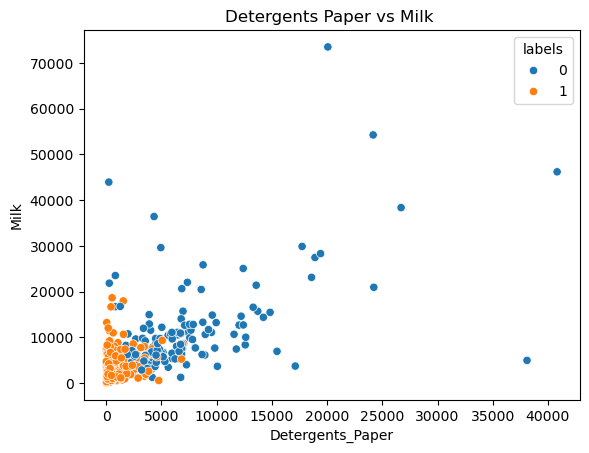

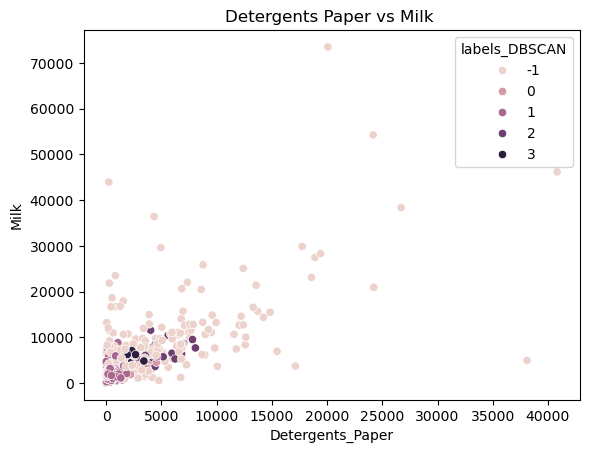

In [29]:
plot(
    clean_customers['Detergents_Paper'],
    clean_customers['Milk'],
    clean_customers['labels']
)

plot(
    clean_customers['Detergents_Paper'],
    clean_customers['Milk'],
    clean_customers['labels_DBSCAN']
)

Visualize `Grocery` as X and `Fresh` as y by `labels` and `labels_DBSCAN` respectively

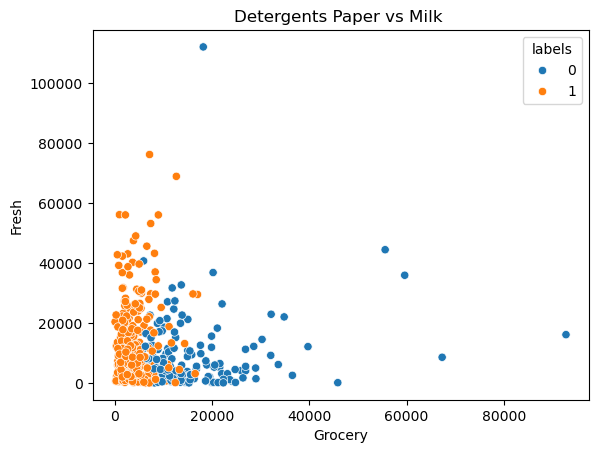

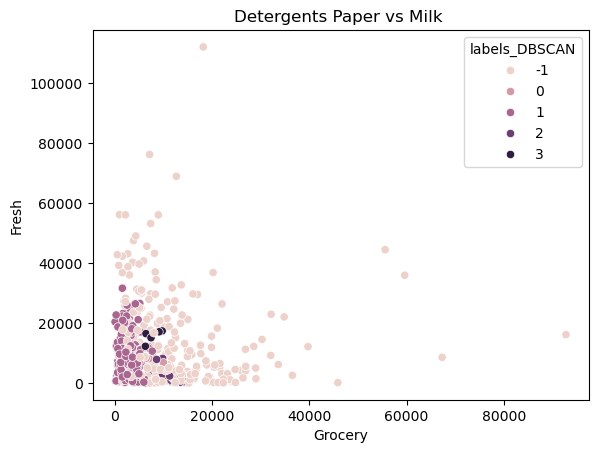

In [27]:
plot(
    clean_customers['Grocery'],
    clean_customers['Fresh'],
    clean_customers['labels']
)

plot(
    clean_customers['Grocery'],
    clean_customers['Fresh'],
    clean_customers['labels_DBSCAN']
)

Visualize `Frozen` as X and `Delicassen` as y by `labels` and `labels_DBSCAN` respectively

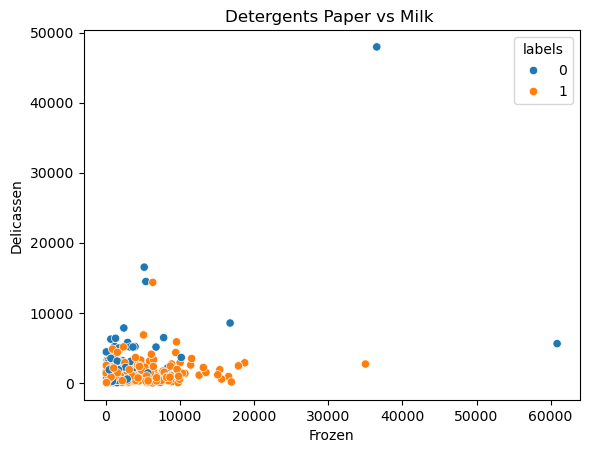

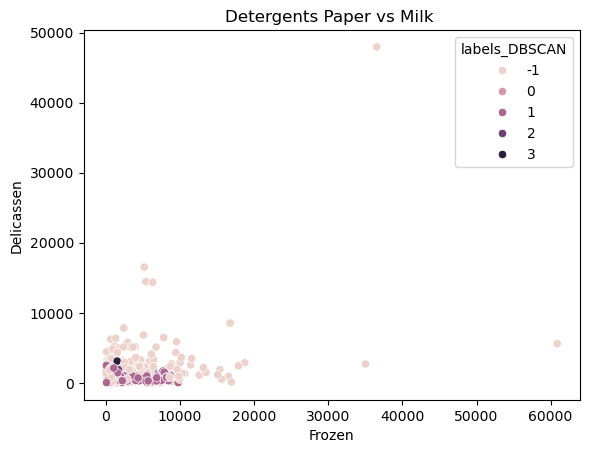

In [30]:
plot(
    clean_customers['Frozen'],
    clean_customers['Delicassen'],
    clean_customers['labels']
)

plot(
    clean_customers['Frozen'],
    clean_customers['Delicassen'],
    clean_customers['labels_DBSCAN']
)

Let's use a groupby to see how the mean differs between the groups. Group `customers` by `labels` and `labels_DBSCAN` respectively and compute the means for all columns.

In [35]:
customers = X.copy()
customers['labels'] = kmeans_2.labels_
customers['labels_DBSCAN'] = labels_dbscan

customers.groupby('labels').mean()
customers.groupby('labels_DBSCAN').mean()

,Channel,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total,labels
labels_DBSCAN,,,,,,,,,
-1,1.514151,15262.613208,9181.905660,12634.646226,4128.391509,4850.599057,2289.075472,48347.231132,0.476415
0,2.000000,9930.125000,3417.125000,6978.750000,800.875000,3532.875000,389.125000,25048.875000,0.125000
1,1.000000,9335.882051,2082.492308,2609.328205,2292.892308,509.302564,745.625641,17575.523077,1.000000
2,2.000000,2567.789474,7115.578947,11159.263158,847.315789,5039.631579,1280.157895,28009.736842,0.000000
3,2.000000,15955.166667,5862.333333,7223.666667,1135.166667,2700.000000,2137.666667,35014.000000,0.000000


Which algorithm appears to perform better?

**Your observations here**

- K-Means provides clearer and more interpretable cluster separation for this dataset. DBSCAN identifies some dense regions but labels many observations as noise, making the segmentation less stable. Therefore, K-Means demonstrates better performance for this dataset.


# Bonus Challenge 2 - Changing K-Means Number of Clusters

As we mentioned earlier, we don't need to worry about the number of clusters with DBSCAN because it automatically decides that based on the parameters we send to it. But with K-Means, we have to supply the `n_clusters` param (if you don't supply `n_clusters`, the algorithm will use `8` by default). You need to know that the optimal number of clusters differs case by case based on the dataset. K-Means can perform badly if the wrong number of clusters is used.

In advanced machine learning, data scientists try different numbers of clusters and evaluate the results with statistical measures (read [here](https://en.wikipedia.org/wiki/Cluster_analysis#External_evaluation)). We are not using statistical measures today but we'll use our eyes instead. In the cells below, experiment with different number of clusters and visualize with scatter plots. What number of clusters seems to work best for K-Means?

In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels_k = kmeans.fit_predict(customers_scale)
    score = silhouette_score(customers_scale, labels_k)
    print(f"K={k}, Silhouette Score={score}")

K=2, Silhouette Score=0.42863911455201853
K=3, Silhouette Score=0.4294856306318785
K=4, Silhouette Score=0.4501725246747528
K=5, Silhouette Score=0.44357107268777113
K=6, Silhouette Score=0.42537338428221483


**Your comment here**

- Based on silhouette analysis, K=4 achieves the highest score (0.45), indicating better separation and cohesion compared to other tested values. Therefore, 4 clusters appear to be the optimal choice for K-Means on this dataset.


# Bonus Challenge 3 - Changing DBSCAN `eps` and `min_samples`

Experiment changing the `eps` and `min_samples` params for DBSCAN. See how the results differ with scatter plot visualization.

In [38]:
from sklearn.cluster import DBSCAN

for eps in [0.3, 0.5, 0.7, 1.0]:
    db = DBSCAN(eps=eps, min_samples=5)
    labels_db = db.fit_predict(customers_scale)
    print(f"eps={eps}, clusters={len(set(labels_db))}, noise={(labels_db==-1).sum()}")

eps=0.3, clusters=3, noise=329
eps=0.5, clusters=5, noise=212
eps=0.7, clusters=4, noise=118
eps=1.0, clusters=4, noise=54


**Your comment here**

-  DBSCAN shows high sensitivity to the eps parameter. Small eps values classify most points as noise, while larger eps values reduce noise but alter the number of clusters significantly. In contrast, K-Means provides more stable and interpretable segmentation for this dataset.